# Предсказание дефолта по кредитной истории

Для каждой заявки оцениваем вероятность события `flag = 1`. Основной критерий — ROC-AUC не ниже 0,75 на отложенных заявках. Ноутбук запускается из папки проекта. Нужны исходные Parquet и CSV. Повторный запуск использует сохранённую таблицу признаков.

Проверенное окружение: Python 3.12, pandas 2.2.3, NumPy 2.3.5, PyArrow 25.0.1, scikit-learn 1.9.1, CatBoost 1.2.10, Matplotlib 3.11.2, cloudpickle 3.1.2 и PyTorch 2.15.0.

**Результат.** Ансамбль нейросети и CatBoost получил ROC-AUC **0.7641** на последних 600 000 заявок. Этот период повторно использован после первоначальной проверки CatBoost, поэтому результат имеет статус исследовательской оценки. Подготовка начинается со всех двенадцати исходных файлов. Кеши признаков и промежуточных моделей ускоряют повторный запуск, их можно восстановить из исходных данных выполнением ячеек по порядку. Для применения готовой модели достаточно файла `credit_pipeline.pkl` и примера в последнем разделе.

Публичная версия ноутбука сохраняет агрегированные выводы. Для повторных расчётов разместите исходные файлы согласно README.

In [1]:
import gc
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from threadpoolctl import threadpool_limits

SEED = 42
target = pd.read_csv("train_target.csv").set_index("id", verify_integrity=True)
assert set(target.flag.unique()) == {0, 1}
parts = sorted(Path("train_data").glob("*.pq"))
raw_rows = sum(pq.ParquetFile(p).metadata.num_rows for p in parts)
sample = next(pq.ParquetFile(parts[0]).iter_batches(batch_size=5)).to_pandas()
print(f"Файлов: {len(parts)}, кредитных продуктов: {raw_rows:,}, заявок: {len(target):,}")
print("Полей в исходной записи:", sample.shape[1])

Файлов: 12, кредитных продуктов: 26,162,717, заявок: 3,000,000


## От продукта к заявке
По справочнику больший `rn` означает более поздний продукт. Набор A описывает длину истории и состояние последнего кредита. Набор B добавляет доли продуктов с каждым двоичным флагом: одна недавняя просрочка и систематические просрочки дают разную историю. Набор C добавляет частоты кодов сроков, лимитов, платежей и статусов. Номера интервалов произвольны, поэтому сумма номеров лишена финансового смысла. Частота конкретного кода сохраняет информацию о составе истории.

Ниже приведён весь код построения признаков. В памяти одновременно находится одна часть данных. Проверяем уникальность ключей и полное совпадение заявок с таблицей меток.

In [2]:
"""Построение признаков заявки из исходных кредитных продуктов."""

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

FLAGS = [
    "is_zero_loans5", "is_zero_loans530", "is_zero_loans3060",
    "is_zero_loans6090", "is_zero_loans90", "is_zero_util",
    "is_zero_over2limit", "is_zero_maxover2limit", "pclose_flag", "fclose_flag",
]
# Фиксированные индикаторы кодов. Код является меткой интервала.
CATEGORIES = {
    "pre_since_opened": 20, "pre_since_confirmed": 18,
    "pre_loans_credit_limit": 20, "pre_util": 20,
    "pre_loans_credit_cost_rate": 14, "pre_till_fclose": 16,
    "enc_loans_credit_type": 8, "enc_loans_credit_status": 8,
    "pre_loans_next_pay_summ": 8, "pre_loans_outstanding": 7,
    "pre_maxover2limit": 20, "enc_paym_0": 5, "enc_paym_1": 5,
}


def aggregate(products):
    """Одна строка на заявку. На входе полные истории выбранных заявок."""
    products = products.sort_values(["id", "rn"])
    if products[["id", "rn"]].isna().any().any() or products.duplicated(["id", "rn"]).any():
        raise ValueError("Нарушена уникальность ключа (id, rn)")
    ids, starts, counts = np.unique(
        products.id.to_numpy(), return_index=True, return_counts=True
    )
    ends = starts + counts - 1
    features = {"loans": counts}
    for col in products.columns.drop(["id", "rn"]):
        values = products[col].to_numpy()
        features[f"last_{col}"] = values[ends]
        if col in FLAGS:
            features[f"share_{col}"] = np.add.reduceat(values, starts) / counts
        if col in CATEGORIES:
            for code in range(CATEGORIES[col]):
                matches = values == code
                features[f"count_{col}_{code}"] = np.add.reduceat(matches, starts)
    return pd.DataFrame(features, index=pd.Index(ids, name="id"), dtype="float32")


def build_dataset(folder, target, destination):
    """Проверяем границы файлов, записываем части, затем объединяем заявки."""
    import pyarrow as pa
    writer = None
    total = 0
    previous = -1
    temporary = destination.with_suffix(".partial")
    try:
        for path in sorted(folder.glob("*.pq"), key=lambda p: int(p.stem.split("_")[-1])):
            table = pq.read_table(path)
            history = table.to_pandas()
            del table
            frame = aggregate(history)
            total += len(history)
            del history
            if frame.index.min() <= previous:
                raise ValueError("Перекрытие диапазонов id между файлами")
            previous = frame.index.max()
            frame["flag"] = target.loc[frame.index, "flag"].to_numpy()
            table = pa.Table.from_pandas(frame.reset_index(), preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(temporary, table.schema, compression="zstd")
            writer.write_table(table)
            print(path.name, len(frame), flush=True)
        writer.close()
        writer = None
        if pq.ParquetFile(temporary).metadata.num_rows != len(target):
            raise ValueError("Часть целевых меток не имеет кредитной истории")
        temporary.replace(destination)
    finally:
        if writer is not None:
            writer.close()
    return total

In [2]:
cache = Path("applications.parquet")
if not cache.exists():
    build_dataset(Path("train_data"), target, cache)
info = pq.ParquetFile(cache)
keys = pd.read_parquet(cache, columns=["id", "flag", "loans"]).set_index("id")
pd.testing.assert_series_equal(keys.flag.sort_index(), target.flag.sort_index())
assert keys.loans.sum() == raw_rows and keys.index.is_monotonic_increasing
print("Размер итоговой таблицы (включая id и flag):", (len(keys), len(info.schema.names)))
print(keys.describe().round(3))

Размер итоговой таблицы (включая id и flag): (3000000, 241)
              flag        loans
count  3000000.000  3000000.000
mean         0.035        8.721
std          0.185        6.176
min          0.000        1.000
25%          0.000        4.000
50%          0.000        7.000
75%          0.000       12.000
max          1.000       58.000


## Проверка на более поздних заявках
Порядок `id` соответствует времени подачи, поэтому первые 80% заявок образуют обучающую выборку, последние 20% — тест. Последнюю четверть обучающей выборки используем как валидацию для сравнения вариантов. Для сопоставимости и экономии времени во всех экспериментах берём одни и те же случайные подвыборки из этих периодов. После выбора конфигурации обучаем её на всех первых 80%. Идентификатор и целевой флаг исключены из признаков.

После первоначальной оценки CatBoost эксперименты были продолжены. Поэтому последние 20% заявок далее обозначают использованный отложенный период. Его разбиение на половины показывает устойчивость внутри периода, но не создаёт независимой проверки.

In [3]:
n = len(keys)
cut, valid_start = int(n * 0.8), int(n * 0.6)
cols = [c for c in info.schema.names if c not in {"id", "flag"}]
last = [c for c in cols if c == "loans" or c.startswith("last_")]
shares = last + [c for c in cols if c.startswith("share_")]
rng = np.random.default_rng(SEED)
def read_rows(indices, columns):
    # Выбираем строки внутри групп Parquet, сохраняя порядок заявок.
    blocks = []
    offset = 0
    for i in range(info.num_row_groups):
        size = info.metadata.row_group(i).num_rows
        selected = indices[(indices >= offset) & (indices < offset + size)]
        if len(selected):
            block = info.read_row_group(i, columns=columns)
            blocks.append(block.take(selected - offset).to_pandas())
        offset += size
    return pd.concat(blocks, ignore_index=True)

train_pos = np.sort(rng.choice(valid_start, 350000, replace=False))
val_pos = np.sort(rng.choice(np.arange(valid_start, cut), 130000, replace=False))
train = read_rows(train_pos, cols)
valid = read_rows(val_pos, cols)
y_train, y_valid = keys.flag.iloc[train_pos], keys.flag.iloc[val_pos]
print(f"Обучение: {(cut, len(cols))}, тест: {(n-cut, len(cols))}")
print(f"Эксперименты: {len(train)} ранних и {len(valid)} последующих заявок")
print(f"Дефолты в обучении: {keys.flag.iloc[:cut].mean():.2%}")

Обучение: (2400000, 239), тест: (600000, 239)
Эксперименты: 350000 ранних и 130000 последующих заявок
Дефолты в обучении: 3.61%


## Эксперименты
Сначала фиксируем CatBoost и сравниваем три набора признаков. На наиболее результативном наборе сравниваем логистическую регрессию, гистограммный градиентный бустинг и CatBoost. Для CatBoost проверяем также более глубокие деревья и больше итераций. Выбираем максимум ROC-AUC на валидации. Average precision показывает качество ранжирования редкого положительного класса.

In [4]:
def make_model(kind, features):
    prep = ColumnTransformer([("features", "passthrough", features)])
    if kind == "Logit":
        estimator = LogisticRegression(max_iter=400, random_state=SEED)
        return Pipeline([("prepare", prep), ("scale", StandardScaler()), ("model", estimator)])
    if kind == "HistGB":
        estimator = HistGradientBoostingClassifier(max_iter=180, max_leaf_nodes=31,
                                                   random_state=SEED)
    else:
        depth, iterations = (5, 300) if kind == "CatBoost 5" else {"CatBoost 7": (7, 550), "CatBoost 8": (8, 850)}[kind]
        estimator = CatBoostClassifier(
            depth=depth, iterations=iterations, learning_rate=0.12,
            thread_count=7, verbose=False, random_seed=SEED, allow_writing_files=False,
        )
    return Pipeline([("prepare", prep), ("model", estimator)])

sets = {"A · последний продукт": last, "B · доли флагов": shares, "C · частоты кодов": cols}
results = []
def experiment(kind, group):
    with threadpool_limits(limits=5):
        pipeline = make_model(kind, sets[group]).fit(train, y_train)
        scores = pipeline.predict_proba(valid)[:, 1]
    results.append(dict(model=kind, features=group, ROC_AUC=roc_auc_score(y_valid, scores),
                        AP=average_precision_score(y_valid, scores)))
    print(results[-1], flush=True)

for group in sets:
    experiment("CatBoost 5", group)
best_group = max(results, key=lambda r: r["ROC_AUC"])["features"]
for kind in ["Logit", "HistGB", "CatBoost 7"]:
    experiment(kind, best_group)
ranking = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
print(ranking.round(5).to_string(index=False))
winner = ranking.iloc[0]
del train, valid
gc.collect()

{'model': 'CatBoost 5', 'features': 'A · последний продукт', 'ROC_AUC': 0.6819154161299884, 'AP': 0.07925939443281822}
{'model': 'CatBoost 5', 'features': 'B · доли флагов', 'ROC_AUC': 0.6990085320255449, 'AP': 0.08159991153987581}
{'model': 'CatBoost 5', 'features': 'C · частоты кодов', 'ROC_AUC': 0.7309585535286033, 'AP': 0.09473992932821718}
{'model': 'Logit', 'features': 'C · частоты кодов', 'ROC_AUC': 0.7132160405270674, 'AP': 0.08210884007766212}
{'model': 'HistGB', 'features': 'C · частоты кодов', 'ROC_AUC': 0.7321232798900597, 'AP': 0.09336586200742046}
{'model': 'CatBoost 7', 'features': 'C · частоты кодов', 'ROC_AUC': 0.7351153674112796, 'AP': 0.09458987035016145}
     model              features  ROC_AUC      AP
CatBoost 7     C · частоты кодов  0.73512 0.09459
    HistGB     C · частоты кодов  0.73212 0.09337
CatBoost 5     C · частоты кодов  0.73096 0.09474
     Logit     C · частоты кодов  0.71322 0.08211
CatBoost 5       B · доли флагов  0.69901 0.08160
CatBoost 5 A · по

## Уточнение оценки по истории отдельных продуктов
Отдельная модель учится на продуктах первых 500 тысяч заявок. Каждый продукт получает метку своей заявки и вес, обратный числу продуктов. У моделей нет таргетов ни из валидации, ни из теста. Чтобы продукт не получил оценку модели, видевшей его метку, для чётных и нечётных id используем модели, обученные на противоположной половине.

Обобщаем оценки внутри заявки: среднее, разброс, крайние значения, риск последнего кредита и трёх последних. Также добавляем состав кредитов без даты фактического закрытия, сколько продуктов открыто после последней просрочки, и частоту статусов платежей за 3, 12 и 25 месяцев. Сначала сравниваем новый набор с прежним при тех же параметрах. Затем проверяем увеличение глубины и числа деревьев.

## Проверка семантики fclose_flag

В description.xlsx указано, что fclose_flag отмечает неопределённость фактического количества дней от открытия до закрытия кредита. Значение 1 означает неопределённый срок. Открытое состояние кредита из этого определения однозначно не следует.

Далее считаем продукты с неопределённым фактическим сроком закрытия. Технические имена признаков с префиксом open_ сохранены для совместимости с обученными весами и кешами. В пояснениях и интерпретации используется точное определение флага.

Проверяем все исходные файлы и сопоставляем fclose_flag с enc_loans_credit_status. Значения статуса закодированы случайными номерами, расшифровка в материалах отсутствует. Таблица показывает связь двух полей. Для подтверждения открытого состояния требуются расшифровка статусов и правила заполнения сроков от поставщика данных.

In [5]:
from collections import Counter
import openpyxl

dictionary = openpyxl.load_workbook("description.xlsx", read_only=True)
for row in dictionary.active.values:
    if row[0] == "fclose_flag":
        print("Определение из справочника:", row[1])
dictionary.close()

status_counts = Counter()
for source in sorted(Path("train_data").glob("*.pq")):
    for batch in pq.ParquetFile(source).iter_batches(
        batch_size=250000, columns=["fclose_flag", "enc_loans_credit_status"]
    ):
        frame = batch.to_pandas()
        assert frame.fclose_flag.isin([0, 1]).all()
        status_counts.update(frame.value_counts().to_dict())
status_table = pd.Series(status_counts).unstack(level=0, fill_value=0)
status_table.index.name = "Код статуса"
status_table.columns.name = "fclose_flag"
status_table["Доля неопределённых сроков"] = (
    status_table[1] / (status_table[0] + status_table[1])
)
assert status_table[[0, 1]].to_numpy().sum() == raw_rows
print(status_table.to_string())
print("Всего продуктов:", raw_rows)
print("Продуктов с неопределённым фактическим сроком:", status_table[1].sum())


Определение из справочника: Флаг: фактическое количество дней с даты открытия кредита до даты закрытия не определено 
fclose_flag         0        1  Доля неопределённых сроков
Код статуса                                               
0                1947       34                    0.017163
1                 799    47769                    0.983549
2             3096017  5180186                    0.625913
3            16838097   723676                    0.041207
4              187978    13980                    0.069222
5               44881    23550                    0.344142
6                2573     1230                    0.323429
Всего продуктов: 26162717
Продуктов с неопределённым фактическим сроком: 5990425


In [6]:
"""Перекрёстная оценка риска кредитного продукта внутри заявки."""
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from catboost import CatBoostClassifier


def product_inputs(history):
    # Сколько более поздних продуктов известно к моменту заявки.
    data = history.drop(columns="id").astype("float32")
    size = history.groupby("id")["rn"].transform("size")
    data["later_products"] = size - history.rn
    data["history_size"] = size
    payments = history.filter(regex=r"^enc_paym_")
    for code in range(5):
        data[f"months_code_{code}"] = (payments == code).sum(axis=1)
    return data


def fit_product_models(paths, target):
    # Первые 500 тыс. заявок принадлежат только обучающему периоду.
    # Для каждого id используем модель, обученную на id другой чётности.
    frames = [pq.read_table(p).to_pandas().astype("int32") for p in paths]
    history = pd.concat(frames, ignore_index=True)
    x = product_inputs(history)
    labels = target.flag.reindex(history.id).to_numpy()
    weights = 1 / x.history_size.to_numpy()
    models = {}
    for parity in (0, 1):
        keep = history.id.to_numpy() % 2 != parity
        model = CatBoostClassifier(depth=7, iterations=500, learning_rate=0.12,
                                   thread_count=6, random_seed=42, verbose=False,
                                   allow_writing_files=False)
        model.fit(x[keep], labels[keep], sample_weight=weights[keep] / weights[keep].mean())
        models[parity] = model
    return models


def product_features(history, models):
    history = history.sort_values(["id", "rn"])
    inputs = product_inputs(history)
    risk = np.empty(len(inputs))
    for parity, model in models.items():
        mask = history.id.to_numpy() % 2 == parity
        if mask.any():
            risk[mask] = model.predict_proba(inputs[mask], thread_count=6)[:, 1]
    loans = pd.DataFrame({"id": history.id.to_numpy(), "risk": risk})
    grouped = loans.groupby("id").risk
    result = grouped.agg(["mean", "max", "min", "last", "first", "std"]).fillna(0)
    recent = loans.groupby("id").tail(3)
    result["recent"] = recent.groupby("id").risk.mean()
    return result.add_prefix("product_risk_").astype("float32")


def history_details(history):
    """Описываем продукты с неопределённым фактическим сроком закрытия и давность просрочек."""
    history = history.sort_values(["id", "rn"])
    ids, starts, sizes = np.unique(history.id, return_index=True, return_counts=True)
    features = {}
    for col in ["pre_since_opened", "pre_loans_credit_limit", "enc_loans_credit_type"]:
        features[f"oldest_{col}"] = history[col].to_numpy()[starts]
    # По description.xlsx флаг означает неопределённый фактический срок.
    # Префикс open_ сохранён для совместимости с обученными весами и кешем.
    # Признаки считают продукты с fclose_flag=1, статус открытия не выводится.
    closure_unknown = history.fclose_flag.to_numpy() == 1
    for col, codes in [("pre_util", 20), ("pre_loans_credit_limit", 20),
                       ("enc_loans_credit_type", 8), ("enc_paym_0", 5),
                       ("pre_loans_outstanding", 7)]:
        values = history[col].to_numpy()
        for code in range(codes):
            features[f"open_{col}_{code}"] = np.add.reduceat(closure_unknown & (values == code), starts)
    for col in [c for c in history if c.startswith("is_zero_loans")]:
        marked = history[col].to_numpy() == 0
        latest = np.maximum.reduceat(np.where(marked, history.rn, -1), starts)
        features[f"loans_since_{col}"] = np.where(latest >= 0, sizes - latest, -1)
        features[f"open_with_{col}"] = np.add.reduceat(closure_unknown & marked, starts)
    for period in [3, 12, 25]:
        payments = history[[f"enc_paym_{i}" for i in range(period)]].to_numpy()
        for code in [1, 2, 3]:
            matches = (payments == code).sum(axis=1)
            features[f"pay_{period}_{code}_mean"] = np.add.reduceat(matches, starts) / sizes
            features[f"pay_{period}_{code}_max"] = np.maximum.reduceat(matches, starts)
    return pd.DataFrame(features, index=pd.Index(ids, name="id"), dtype="float32")


In [7]:
def add_history_features(source, destination, models):
    files = sorted(Path("train_data").glob("*.pq"), key=lambda p: int(p.stem.split("_")[-1]))
    original = pq.ParquetFile(source)
    import pyarrow as pa
    writer = None
    temporary = destination.with_suffix(".partial")
    try:
        for i, file in enumerate(files):
            history = pq.read_table(file).to_pandas().astype("int32")
            extra = history_details(history).join(product_features(history, models))
            base = original.read_row_group(i).to_pandas().set_index("id")
            assert base.index.equals(extra.index)
            enhanced = base.join(extra).reset_index()
            table = pa.Table.from_pandas(enhanced, preserve_index=False)
            if writer is None:
                writer = pq.ParquetWriter(temporary, table.schema, compression="zstd")
            writer.write_table(table)
            print(file.name, flush=True)
        writer.close()
        writer = None
        temporary.replace(destination)
    finally:
        if writer is not None:
            writer.close()


In [6]:
base_file = Path("product_models.pkl")
if base_file.exists():
    with base_file.open("rb") as stream:
        product_models = pickle.load(stream)
else:
    paths = sorted(parts, key=lambda p: int(p.stem.split("_")[-1]))
    product_models = fit_product_models(paths[:2], target)
    with base_file.open("wb") as stream:
        pickle.dump(product_models, stream)
extended = Path("histories.parquet")
if not extended.exists():
    add_history_features(cache, extended, product_models)
info = pq.ParquetFile(extended)
cols = [c for c in info.schema.names if c not in {"id", "flag"}]
print("Расширенная таблица:", (info.metadata.num_rows, len(info.schema.names)))
sets["D · история и риск продуктов"] = cols
train = read_rows(train_pos, cols)
valid = read_rows(val_pos, cols)
for kind in ["CatBoost 7", "CatBoost 8"]:
    experiment(kind, "D · история и риск продуктов")
ranking = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
print(ranking.round(5).to_string(index=False))
winner = ranking.iloc[0]
del train, valid
gc.collect()

train_data_0.pq
train_data_1.pq
train_data_2.pq
train_data_3.pq
train_data_4.pq
train_data_5.pq
train_data_6.pq
train_data_7.pq
train_data_8.pq
train_data_9.pq
train_data_10.pq
train_data_11.pq
Расширенная таблица: (3000000, 339)
{'model': 'CatBoost 7', 'features': 'D · история и риск продуктов', 'ROC_AUC': 0.7420510998895207, 'AP': 0.09991655969721627}
{'model': 'CatBoost 8', 'features': 'D · история и риск продуктов', 'ROC_AUC': 0.7377738300773355, 'AP': 0.09621266347969251}
     model                     features  ROC_AUC      AP
CatBoost 7 D · история и риск продуктов  0.74205 0.09992
CatBoost 8 D · история и риск продуктов  0.73777 0.09621
CatBoost 7            C · частоты кодов  0.73512 0.09459
    HistGB            C · частоты кодов  0.73212 0.09337
CatBoost 5            C · частоты кодов  0.73096 0.09474
     Logit            C · частоты кодов  0.71322 0.08211
CatBoost 5              B · доли флагов  0.69901 0.08160
CatBoost 5        A · последний продукт  0.68192 0.07926


## Первоначальная оценка CatBoost на отложенном периоде
Файл прогнозов содержит идентификатор заявки, вероятность дефолта и прогноз класса по стандартному порогу 0,5. Для ROC-AUC используем непрерывную вероятность. Проверим также устойчивость по последовательным половинам тестового периода.

In [7]:
selected = sets[winner.features]
def load_period(start, stop):
    values = np.empty((stop - start, len(selected)), dtype=np.float32, order="F")
    offset = 0
    for i in range(info.num_row_groups):
        end = offset + info.metadata.row_group(i).num_rows
        left, right = max(offset, start), min(end, stop)
        if left < right:
            block = info.read_row_group(i, columns=selected).slice(left-offset, right-left)
            for j, name in enumerate(selected):
                values[left-start:right-start, j] = block[name].to_numpy()
        offset = end
    return pd.DataFrame(values, columns=selected, copy=False)

def fit_period(stop):
    frame = load_period(0, stop)
    with threadpool_limits(limits=6):
        return make_model(winner.model, selected).fit(frame, keys.flag.iloc[:stop])

evaluated = fit_period(cut)
test = load_period(cut, n)
scores = evaluated.predict_proba(test)[:, 1]
truth = keys.flag.iloc[cut:]
predictions = pd.DataFrame({"id": truth.index, "probability": scores,
                            "prediction": (scores >= 0.5).astype(int)})
predictions.to_csv("test_predictions.csv", index=False)
assert predictions.id.is_unique and predictions.probability.between(0, 1).all()
print("ROC-AUC:", roc_auc_score(truth, scores), "AP:", average_precision_score(truth, scores))
print("Доля дефолтов:", truth.mean())
for pos in np.array_split(np.arange(len(truth)), 2):
    print("ROC-AUC по половине периода:", roc_auc_score(truth.iloc[pos], scores[pos]))

ROC-AUC: 0.7451412825865888 AP: 0.09750009326112362
Доля дефолтов: 0.03317166666666667
ROC-AUC по половине периода: 0.7466170018812827
ROC-AUC по половине периода: 0.7431533063761359


В нижней группе дефолтов 0.43%, в верхней — 10.83%.
Вклад признаков в модель (не причинный эффект):
product_risk_mean                21.75
product_risk_recent              11.31
product_risk_min                  6.21
product_risk_std                  3.45
count_enc_loans_credit_type_0     2.72
product_risk_last                 2.21
share_is_zero_loans530            2.17
count_pre_loans_outstanding_1     1.80
count_pre_util_3                  1.79
product_risk_max                  1.71
dtype: float64


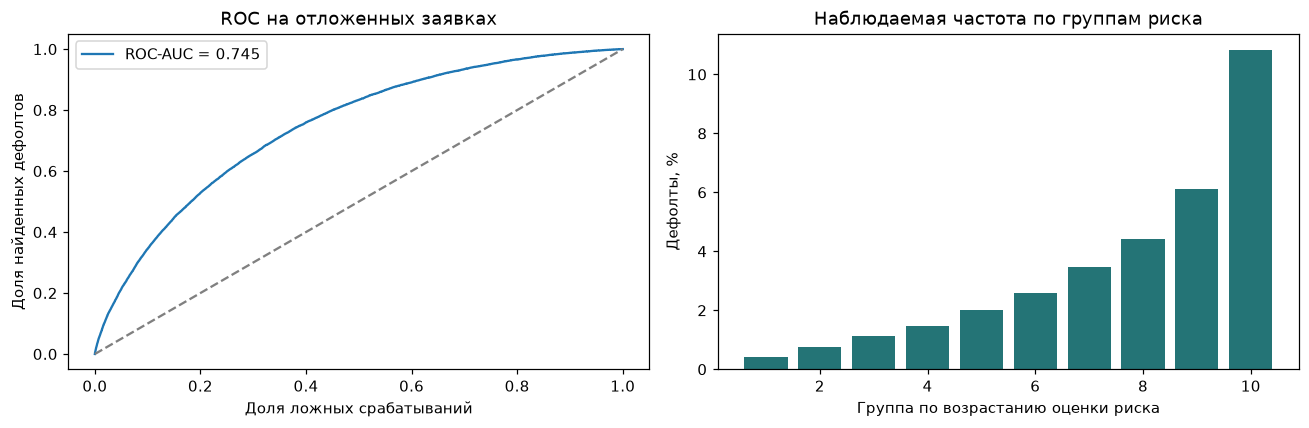

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fpr, tpr, _ = roc_curve(truth, scores)
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(truth, scores):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set(xlabel="Доля ложных срабатываний", ylabel="Доля найденных дефолтов",
            title="ROC на отложенных заявках")
axes[0].legend()
deciles = pd.qcut(pd.Series(scores), 10, labels=False, duplicates="drop")
rates = truth.reset_index(drop=True).groupby(deciles).mean() * 100
axes[1].bar(rates.index + 1, rates, color="#247476")
axes[1].set(xlabel="Группа по возрастанию оценки риска", ylabel="Дефолты, %",
            title="Наблюдаемая частота по группам риска")
fig.tight_layout()
plt.show()
print(f"В нижней группе дефолтов {rates.iloc[0]:.2f}%, в верхней — {rates.iloc[-1]:.2f}%.")
model = evaluated.named_steps["model"]
if hasattr(model, "feature_importances_"):
    importance = pd.Series(model.feature_importances_, index=selected).nlargest(10)
    print("Вклад признаков в модель (не причинный эффект):")
    print(importance.round(2))
del test, evaluated, model
gc.collect()

## Финальная модель и применение
После измерения качества переобучаем выбранный пайплайн на всех 3 млн заявок. В pickle включаем подготовку признаков и вспомогательные модели. Пайплайн принимает как готовую таблицу признаков, так и исходные строки кредитных историй. Для сырых данных возвращается один результат на заявку в порядке возрастания id. Метрику воспроизводит файл с прогнозами, записанный до финального обучения.

In [9]:
final = fit_period(n)
from sklearn.preprocessing import FunctionTransformer
import cloudpickle

def prepare_applications(frame, models, expanded):
    if "rn" not in frame:
        return frame
    base = aggregate(frame)
    if expanded:
        base = base.join(history_details(frame)).join(product_features(frame, models))
    return base

prepare = FunctionTransformer(
    prepare_applications,
    kw_args={"models": product_models, "expanded": winner.features.startswith("D")},
)
prepare.fit(load_period(0, 1))
final = Pipeline([("history", prepare), *final.steps])
with open("credit_pipeline.pkl", "wb") as stream:
    cloudpickle.dump(final, stream, protocol=pickle.HIGHEST_PROTOCOL)
with open("credit_pipeline.pkl", "rb") as stream:
    loaded = pickle.load(stream)
probe = load_period(n-12, n)
np.testing.assert_allclose(loaded.predict_proba(probe), final.predict_proba(probe))
np.testing.assert_array_equal(loaded.predict(probe), final.predict(probe))
assert len(pd.read_csv("test_predictions.csv", usecols=["id"])) == n-cut
raw = next(pq.ParquetFile(parts[0]).iter_batches(batch_size=200)).to_pandas()
raw = raw.loc[raw.id < raw.id.max()]
ids = np.sort(raw.id.unique())
np.testing.assert_allclose(loaded.predict_proba(raw),
                           loaded.predict_proba(read_rows(ids, selected)))
print("Совпадают прогнозы из сырых продуктов и из готовых признаков.")

Совпадают прогнозы из сырых продуктов и из готовых признаков.


## Модель последовательности кредитов
У лучшей модели на агрегатах тестовый ROC-AUC составил 0,7451. Добавим нейросеть, которая совместно обучает представление продукта и прогноз по заявке. Тестовый период уже использовался для оценки предыдущего подхода. Все последующие настройки сравниваем только на прежней валидации.

Для каждого поля сеть обучает вектор кода. Она учитывает, сколько продуктов появилось позже данного кредита, и отдельно передаёт последнюю запись, среднее, максимум и среднее с повышенным весом недавних продуктов. Это сохраняет сочетания признаков внутри одного кредита. Число эпох выбирается по ROC-AUC на более поздней валидации.

In [12]:
"""Нейросеть для кредитных историй переменной длины."""
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
from torch import nn
from sklearn.metrics import roc_auc_score


def pack_history(history, columns):
    history = history.sort_values(["id", "rn"])
    values = history[columns].to_numpy()
    if values.min() < 0 or values.max() >= 64:
        raise ValueError("Код продукта выходит за диапазон словаря")
    return values.astype("uint8"), history.groupby("id", sort=True).size().to_numpy()


def load_products(folder):
    paths = sorted(Path(folder).glob("*.pq"), key=lambda p: int(p.stem.split("_")[-1]))
    columns = [c for c in pq.ParquetFile(paths[0]).schema.names if c not in ("id", "rn")]
    total = sum(pq.ParquetFile(p).metadata.num_rows for p in paths)
    tokens = np.empty((total, len(columns)), dtype="uint8")
    counts, ids = [], []
    offset = 0
    for path in paths:
        hist = pq.read_table(path).to_pandas()
        values, sizes = pack_history(hist, columns)
        tokens[offset:offset + len(values)] = values
        offset += len(values)
        counts.extend(sizes)
        ids.append(np.unique(hist.id))
    return tokens, np.r_[0, np.cumsum(counts)], np.concatenate(ids), columns


class CreditNet(nn.Module):
    def __init__(self, fields):
        super().__init__()
        self.embedding = nn.Embedding(fields * 64, 5)
        self.register_buffer("offset", torch.arange(fields) * 64)
        self.loan = nn.Sequential(nn.Linear(fields * 5 + 2, 96), nn.BatchNorm1d(96),
                                  nn.SiLU(), nn.Linear(96, 48), nn.SiLU())
        self.transition = nn.Sequential(nn.Linear(96, 48), nn.SiLU())
        self.head = nn.Sequential(nn.Linear(48 * 4 + 1, 80), nn.BatchNorm1d(80),
                                  nn.SiLU(), nn.Dropout(0.15), nn.Linear(80, 1))

    def forward(self, tokens, lengths, positions):
        relative = positions / (lengths.repeat_interleave(lengths) - 1).clamp_min(1)
        x = self.embedding(tokens.long() + self.offset).flatten(1)
        x = self.loan(torch.cat([x, relative[:, None], positions.log1p()[:, None]], 1))
        # У первого кредита в истории предыдущего продукта нет.
        first = torch.zeros(len(x), dtype=torch.bool, device=x.device)
        first[lengths.cumsum(0) - lengths] = True
        prior = torch.roll(x, shifts=1, dims=0) * (~first)[:, None]
        x = x + self.transition(torch.cat([prior, x], 1))
        avg = torch.segment_reduce(x, "mean", lengths=lengths)
        high = torch.segment_reduce(x, "max", lengths=lengths)
        ends = lengths.cumsum(0) - 1
        latest = x[ends]
        # Усиливаем вклад нескольких недавно открытых кредитов.
        weight = (positions * -0.5).exp()
        recent = torch.segment_reduce(x * weight[:, None], "sum", lengths=lengths)
        recent = recent / torch.segment_reduce(weight, "sum", lengths=lengths)[:, None]
        pooled = torch.cat([avg, high, latest, recent, lengths.log1p()[:, None]], 1)
        return self.head(pooled).flatten()


def batch_inputs(tokens, starts, indices):
    sizes = starts[indices + 1] - starts[indices]
    positions = np.arange(sizes.sum()) - np.repeat(sizes.cumsum() - sizes, sizes)
    rows = np.repeat(starts[indices], sizes) + positions
    reverse = np.repeat(sizes - 1, sizes) - positions
    return (torch.from_numpy(tokens[rows]), torch.from_numpy(sizes),
            torch.from_numpy(reverse.astype("float32")))


def probabilities(net, tokens, starts, indices):
    net.eval()
    with torch.inference_mode():
        return np.concatenate([
            net(*batch_inputs(tokens, starts, indices[i:i + 1536])).sigmoid().numpy()
            for i in range(0, len(indices), 1536)
        ])


def train_network(tokens, starts, labels, stop, epochs, valid=None):
    import copy
    torch.manual_seed(42)
    torch.set_num_threads(4)
    rng = np.random.default_rng(42)
    net = CreditNet(tokens.shape[1])
    opt = torch.optim.AdamW(net.parameters(), lr=0.0015)
    best_auc = -1
    best_epoch = epochs
    best_weights = None
    history = []
    for epoch in range(1, epochs + 1):
        net.train()
        order = rng.permutation(stop)
        for group in opt.param_groups:
            group["lr"] = 0.0015 * 0.80 ** (epoch - 1)
        for i in range(0, stop, 1536):
            ids = order[i:i + 1536]
            if len(ids) == 1:
                continue
            logits = net(*batch_inputs(tokens, starts, ids))
            y = torch.from_numpy(labels[ids].astype("float32"))
            loss = nn.functional.binary_cross_entropy_with_logits(logits, y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        if valid is not None:
            pred = probabilities(net, tokens, starts, valid)
            auc = roc_auc_score(labels[valid], pred)
            history.append(auc)
            if auc > best_auc:
                best_epoch, best_auc = epoch, auc
                best_weights = copy.deepcopy(net.state_dict())
            print(f"Эпоха {epoch}: ROC-AUC на валидации {auc:.5f}", flush=True)
        else:
            print(f"Эпоха {epoch}/{epochs}", flush=True)
    if best_weights is not None:
        net.load_state_dict(best_weights)
    net.eval()
    return net, best_epoch, history

In [10]:
tokens, starts, ordered_ids, fields = load_products("train_data")
assert np.array_equal(ordered_ids, keys.index.to_numpy())
labels = keys.flag.to_numpy()
validation_net, best_epoch, curve = train_network(tokens, starts, labels, valid_start, 5, val_pos)
nn_val = probabilities(validation_net, tokens, starts, val_pos)
print("Выбрана эпоха:", best_epoch)

Эпоха 1: ROC-AUC на валидации 0.75309
Эпоха 2: ROC-AUC на валидации 0.75965
Эпоха 3: ROC-AUC на валидации 0.76590
Эпоха 4: ROC-AUC на валидации 0.76543
Эпоха 5: ROC-AUC на валидации 0.76724
Выбрана эпоха: 5


### Выбор модели по валидации
Сравниваем нейросеть, CatBoost и средневзвешенное их вероятностей. Обе модели обучены на одном раннем периоде из 1,8 млн заявок. Вес нейросети выбираем среди 0, 0,25, 0,5, 0,75 и 1.

In [11]:
validation_file = Path("catboost_validation.npy")
if validation_file.exists():
    tree_val = np.load(validation_file)
else:
    validation_tree = fit_period(valid_start)
    tree_val = validation_tree.predict_proba(read_rows(val_pos, selected))[:, 1]
    np.save(validation_file, tree_val)
    del validation_tree
validation_results = []
for w in [0, 0.25, 0.5, 0.75, 1]:
    mix = w * nn_val + (1 - w) * tree_val
    validation_results.append((w, roc_auc_score(labels[val_pos], mix)))
weight, best_auc = max(validation_results, key=lambda row: row[1])
print(pd.DataFrame(validation_results, columns=["Вес нейросети", "ROC-AUC"]))
print("Выбранный вес:", weight)

   Вес нейросети   ROC-AUC
0           0.00  0.751633
1           0.25  0.762214
2           0.50  0.767000
3           0.75  0.768397
4           1.00  0.767238
Выбранный вес: 0.75


### Повторная оценка на отложенном периоде и финальное обучение
Для теста заново обучаем нейросеть на первых 80% с выбранным числом эпох. Берём сохранённые вероятности CatBoost, рассчитанные на тех же заявках до его финального переобучения. Затем обучаем модель для передачи на всех данных и проверяем прогноз после загрузки из pickle.

Эпоха 1/5
Эпоха 2/5
Эпоха 3/5
Эпоха 4/5
Эпоха 5/5
Финальный ROC-AUC: 0.7641232106844541
Average precision: 0.10690311324400642
ROC-AUC по половине теста: 0.7651354113240086
ROC-AUC по половине теста: 0.762695894671354


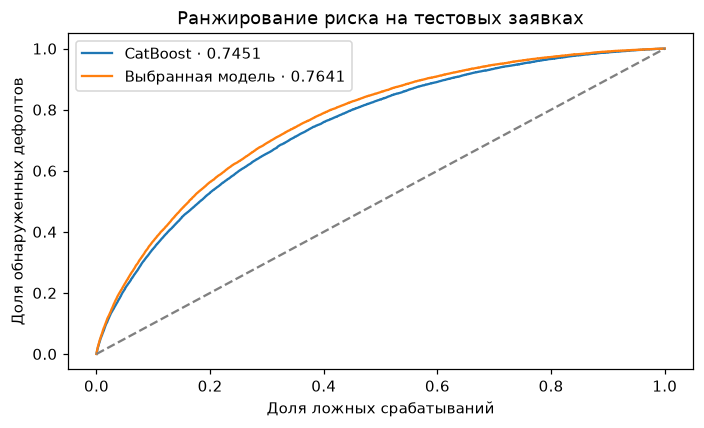

In [12]:
tree_predictions = pd.read_csv("test_predictions.csv").set_index("id")
assert tree_predictions.index.equals(keys.index[cut:])
test_net, _, _ = train_network(tokens, starts, labels, cut, best_epoch)
nn_test = probabilities(test_net, tokens, starts, np.arange(cut, n))
final_scores = weight * nn_test + (1 - weight) * tree_predictions.probability.to_numpy()
truth = keys.flag.iloc[cut:]
predictions = pd.DataFrame({"id": truth.index, "probability": final_scores,
                            "prediction": (final_scores >= 0.5).astype(int)})
predictions.to_csv("test_predictions.csv", index=False)
print("Финальный ROC-AUC:", roc_auc_score(truth, final_scores))
print("Average precision:", average_precision_score(truth, final_scores))
for pos in np.array_split(np.arange(len(truth)), 2):
    print("ROC-AUC по половине теста:", roc_auc_score(truth.iloc[pos], final_scores[pos]))
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, values in [("CatBoost", tree_predictions.probability), ("Выбранная модель", final_scores)]:
    fpr, tpr, _ = roc_curve(truth, values)
    ax.plot(fpr, tpr, label=f"{name} · {roc_auc_score(truth, values):.4f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="Доля ложных срабатываний", ylabel="Доля обнаруженных дефолтов",
       title="Ранжирование риска на тестовых заявках")
ax.legend()
fig.tight_layout()
plt.show()

In [16]:
from sklearn.base import BaseEstimator, ClassifierMixin


class RiskEnsemble(ClassifierMixin, BaseEstimator):
    """Объединение вероятностей CatBoost и сети, учитывающей порядок продуктов."""
    def __init__(self, tree, weight, epochs):
        self.tree = tree
        self.weight = weight
        self.epochs = epochs

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            columns = [c for c in X if c not in ("id", "rn")]
            tokens, counts = pack_history(X, columns)
            starts, ids = np.r_[0, counts.cumsum()], np.sort(X.id.unique())
        else:
            tokens, starts, ids, columns = X
        ordered = y.loc[ids].to_numpy() if isinstance(y, pd.Series) else np.asarray(y)
        if len(ordered) != len(ids):
            raise ValueError("Требуется одна целевая метка на заявку")
        if isinstance(X, pd.DataFrame):
            # При повторном fit на новых историях переобучаем классификатор.
            # Модели формирования продуктовых признаков остаются фиксированными.
            import copy
            self.tree_ = copy.deepcopy(self.tree).fit(X, ordered)
        else:
            # Для полного корпуса здесь уже передан CatBoost, обученный выше
            # на тех же заявках. Кортеж содержит их компактное представление.
            self.tree_ = self.tree
        self.columns_ = columns
        self.classes_ = np.array([0, 1])
        self.network_, _, _ = train_network(tokens, starts, ordered, len(ids), self.epochs)
        return self

    def predict_proba(self, X):
        tokens, counts = pack_history(X, self.columns_)
        p_nn = probabilities(self.network_, tokens, np.r_[0, counts.cumsum()],
                             np.arange(len(counts)))
        p = self.weight * p_nn
        if self.weight < 1:
            p = p + (1 - self.weight) * self.tree_.predict_proba(X)[:, 1]
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [13]:
from sklearn.preprocessing import FunctionTransformer
import cloudpickle

with open("credit_pipeline.pkl", "rb") as stream:
    full_tree = pickle.load(stream)
ensemble = Pipeline([("model", RiskEnsemble(full_tree, weight, best_epoch))])
ensemble.fit((tokens, starts, ordered_ids, fields), keys.flag)
with open("credit_pipeline.pkl", "wb") as stream:
    cloudpickle.dump(ensemble, stream)
with open("credit_pipeline.pkl", "rb") as stream:
    reloaded = pickle.load(stream)
raw = next(pq.ParquetFile(parts[0]).iter_batches(batch_size=200)).to_pandas()
raw = raw[raw.id < raw.id.max()]
np.testing.assert_allclose(reloaded.predict_proba(raw), ensemble.predict_proba(raw))
print("Прогнозы ансамбля совпадают после загрузки.")

Эпоха 1/5
Эпоха 2/5
Эпоха 3/5
Эпоха 4/5
Эпоха 5/5


## Выводы

На 600 000 более поздних заявок **ROC-AUC равен 0.7641**, при ориентире 0,75. Оценка получена на периоде, уже использованном для первоначальной проверки CatBoost. Она описывает результат эксперимента и требует подтверждения на новом независимом периоде. По последовательным половинам тестового периода значения составили 0.7651 и 0.7627. Average precision равна 0.1069 при доле дефолтов 3.32%.

В десяти процентах заявок с наибольшим прогнозируемым риском дефолт наблюдался в 11.59% случаев, в нижней десятой части — в 0.33%. Это демонстрирует, как ранжирование выделяет группу повышенного риска. Порог 0,5 в CSV служит для воспроизведения стандартного прогноза класса. Для выбора рабочего порога банку потребовались бы стоимость пропущенного дефолта и стоимость ошибочного отказа.

На валидации частоты кодов по кредитной истории подняли ROC-AUC CatBoost глубины 5 с 0,6990 до 0,7310. При глубине 7 добавление сведений о продуктах с неопределённым фактическим сроком закрытия, просрочках и продуктовых оценках повысило ROC-AUC с 0,7351 до 0,7421. Более глубокий вариант дал 0,7378 и уступил выбранному.

После первоначальной оценки CatBoost (0,7451) мы проверили модель последовательности кредитов. На валидации вес нейросети в выбранном прогнозе составил 0.75, число эпох — 5. Итоговая оценка использует тот же тестовый период, что и первоначальная проверка. Для следующей независимой проверки потребуется новый период наблюдений.

### Как использовать модель

Запустите код в окружении с версиями библиотек, указанными в начале работы. В `products` должны быть все строки кредитной истории каждой оцениваемой заявки и исходные имена полей. На выходе вероятности расположены по возрастанию идентификаторов заявок.

```python
import pickle
import pandas as pd

with open("credit_pipeline.pkl", "rb") as stream:
    pipeline = pickle.load(stream)

risk = pd.Series(pipeline.predict_proba(products)[:, 1],
                 index=sorted(products.id.unique()), name="probability")
```


## Независимая проверка на новом временном периоде

Все 3 млн заявок уже использованы при финальном обучении. Внутри этих данных невозможно задним числом выделить полностью независимый период для существующего пайплайна.

Перед получением новых данных фиксируем текущий пайплайн, подготовку признаков, вес нейросети 0,75 и число эпох 5. Следующая ячейка проверяет новые заявки с id больше максимального обучающего id и рассчитывает ROC-AUC без изменения модели. Такое условие применимо при сохранении общей временной нумерации id поставщиком. Если нумерация изменилась, временную границу нужно подтвердить по исходным датам.

Новые данные должны содержать полные истории заявок и созревшие целевые метки, определённые по тем же правилам и на том же горизонте. Результат следующей проверки следует записать до любых дальнейших экспериментов. Если затем модель изменится, ей потребуется следующий независимый период.

In [ ]:
def evaluate_future_period(products, new_target, model_path="credit_pipeline.pkl"):
    """Оценка фиксированной модели на новых заявках с общей нумерацией id."""
    labels = new_target.set_index("id", verify_integrity=True)["flag"].sort_index()
    historical_ids = pd.read_csv("train_target.csv", usecols=["id"])["id"]
    if labels.empty or labels.index.min() <= historical_ids.max():
        raise ValueError("Нужны заявки из нового временного периода после обучающего.")
    if set(labels.unique()) != {0, 1}:
        raise ValueError("Для ROC-AUC необходимы оба класса целевой переменной.")
    ids = np.sort(products.id.unique())
    if not np.array_equal(ids, labels.index.to_numpy()):
        raise ValueError("Состав заявок и целевых меток должен полностью совпадать.")
    if products.duplicated(["id", "rn"]).any():
        raise ValueError("Дубли ключа (id, rn) в кредитной истории.")
    with open(model_path, "rb") as stream:
        frozen_model = pickle.load(stream)
    probability = frozen_model.predict_proba(products)[:, 1]
    return {
        "applications": len(labels),
        "default_rate": labels.mean(),
        "ROC_AUC": roc_auc_score(labels, probability),
        "average_precision": average_precision_score(labels, probability),
    }

# После получения нового периода:
# evaluate_future_period(new_products, new_target)


## Уточнения методики

Проверены определение fclose_flag в справочнике и распределения по всем исходным продуктам. Уточнены смысл производных признаков и их комментарии, включая функцию внутри сохранённого пайплайна. Проверено точное совпадение признаков и вероятностей до и после уточнения кода на примере новых строк из исходных файлов.

ROC-AUC 0,7641 обозначен исследовательской оценкой на повторно использованном периоде. Добавлен протокол и функция проверки на новом периоде. Новые данные для этой проверки в материалах отсутствуют, поэтому независимая метрика пока не рассчитана.

Обучение моделей и исторические результаты ячеек сохранены из исходного исследования. В этой редакции повторно выполнены аудит семантики, проверки совместимости модели и валидация структуры ноутбука. VotingClassifier остаётся возможным направлением дальнейших экспериментов.